# Analisis Hasil Eksperimen

**Bangun `networkDefinition.json` (infrastruktur)**

* Menjelaskan **topologi jaringan**:

  * Device apa saja (fog node, cloud, gateway, sensor).
  * Spesifikasi tiap device (IPT, RAM, dsb.).
  * Link antar device (bandwidth & delay).
* ➝ ini adalah **peta infrastruktur** yang jadi “panggung” untuk aplikasi dan user.

**Desain `appDefinition.json` (arsitektur aplikasi)**

* Menjelaskan **aplikasi yang berjalan di atas jaringan**:

  * Modul apa saja (service komputasi).
  * Kebutuhan resource tiap modul (MIPS, RAM).
  * Alur pesan antar modul (graph aplikasi).
* ➝ ini adalah **rancangan software** yang akan ditempatkan ke perangkat pada topologi.

**Deklarasi `usersDefinition.json` (workload user)**

* Menjelaskan **bagaimana pengguna memicu aplikasi**:

  * User X terhubung ke device Y (gateway).
  * User itu menjalankan App Z.
  * Request rate (`lambda`) menunjukkan seberapa sering user mengirim request.
* ➝ ini adalah **traffic generator** yang men-drive aplikasi di dalam topologi.

In [19]:
import json
import pandas as pd
import os
import networkx as nx
import datetime as dt
import numpy as np
import networkx as nx
import math
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

In [20]:
# --- Definisikan data_path ---
data_path = "/Users/adhitya/Project/exp/"   # ganti sesuai path kamu

with open(data_path + 'data/networkDefinition.json', 'r') as file:
    network_definition = json.load(file)

with open(data_path + 'data/appDefinition.json', 'r') as file:
    app_definition = json.load(file)

with open(data_path + 'data/usersDefinition.json', 'r') as file:
    users_def = json.load(file)

# 1. Network Definition

In [21]:
"""
Struktur dari networkDefinition.json:
{"entity": [
    list of device, each with:
    {
        id: int,      # id dari device/node
        RAM: int,     # RAM dari device (MB)
        IPT: int,     # IPT (Instruction Per Time) dari device (instr/ms)
        TB: float,    # storage dari device (TB)
        TYPE: string, # tipe dari device: CLOUD, FG, CFG, FOG
    }
]},
{"link": [
    list of edge/link, each with:
    {
        s: int,       # source node id
        d: int,       # destination node id
        PR: int,      # propagation time (ms) atau delay saat propagasi
        BW: int,      # bandwidth dari link (bytes/ms)
    }
]}
"""

'\nStruktur dari networkDefinition.json:\n{"entity": [\n    list of device, each with:\n    {\n        id: int,      # id dari device/node\n        RAM: int,     # RAM dari device (MB)\n        IPT: int,     # IPT (Instruction Per Time) dari device (instr/ms)\n        TB: float,    # storage dari device (TB)\n        TYPE: string, # tipe dari device: CLOUD, FG, CFG, FOG\n    }\n]},\n{"link": [\n    list of edge/link, each with:\n    {\n        s: int,       # source node id\n        d: int,       # destination node id\n        PR: int,      # propagation time (ms) atau delay saat propagasi\n        BW: int,      # bandwidth dari link (bytes/ms)\n    }\n]}\n'

## 1.1 Topologi

In [22]:
G = nx.Graph()

# Tambahkan node dengan semua atribut
for node in network_definition['entity']:
    node_id = node['id']
    node_attrs = {k: v for k, v in node.items() if k != 'id'}
    G.add_node(node_id, **node_attrs)

print(f"Total nodes ditambahkan: {G.number_of_nodes()}")

# Tambahkan edge dengan semua atribut
for link in network_definition['link']:
    source = link['s']
    dest = link['d']
    edge_attrs = {k: v for k, v in link.items() if k not in ['s', 'd']}
    G.add_edge(source, dest, **edge_attrs)

print(f"Total edges ditambahkan: {G.number_of_edges()}")

# Tampilkan contoh node dengan atribut
if G.nodes():
    sample_node = list(G.nodes(data=True))[0]
    print(f"\nSampel node: {sample_node}")

# Tampilkan contoh edge dengan atribut
if G.edges():
    sample_edge = list(G.edges(data=True))[0]
    print(f"Sampel edge: {sample_edge}")

# Kategorisasi node berdasarkan type
node_types = {}
for node_id, attrs in G.nodes(data=True):
    node_type = attrs.get('type', 'FOG')  # default FOG jika tidak ada type
    if node_type not in node_types:
        node_types[node_type] = []
    node_types[node_type].append(node_id)

print("\nDistribusi node berdasarkan jenisnya:")
for node_type, nodes in node_types.items():
    print(f"{node_type}: {len(nodes)} nodes - {nodes}")   

Total nodes ditambahkan: 101
Total edges ditambahkan: 201

Sampel node: (0, {'RAM': 10, 'IPT': 770, 'TB': 4.276883106405917, 'type': 'CFG'})
Sampel edge: (0, 1, {'PR': 5, 'BW': 75000})

Distribusi node berdasarkan jenisnya:
CFG: 5 nodes - [0, 1, 2, 9, 17]
FOG: 70 nodes - [3, 4, 5, 6, 8, 10, 11, 12, 13, 14, 15, 16, 18, 19, 20, 21, 22, 23, 24, 26, 27, 28, 29, 30, 33, 34, 35, 36, 38, 39, 40, 42, 43, 45, 46, 48, 50, 51, 52, 53, 55, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71, 72, 75, 78, 81, 82, 83, 84, 87, 88, 91, 92, 95, 96, 97, 98]
FG: 25 nodes - [7, 25, 31, 32, 37, 41, 44, 47, 49, 54, 56, 57, 73, 74, 76, 77, 79, 80, 85, 86, 89, 90, 93, 94, 99]
CLOUD: 1 nodes - [100]


## 1.2 Spesifikasi

In [23]:
# Ambil entity list dari networkDefinition.json
entities = pd.DataFrame(network_definition["entity"])
links = pd.DataFrame(network_definition["link"])

# Tampilkan tabel spesifikasi lengkap
print("=== Detail Spesifikasi Semua Device ===")
print(entities[["id","type","IPT","RAM"]].sort_values("type"))

# --- Tampilkan tabel link lengkap ---
print("=== Detail Links Semua Device ===")
print(links[["s", "d", "PR", "BW"]].sort_values("d"))

# Buat folder 'network' jika belum ada
os.makedirs("1. network/", exist_ok=True)

# Simpan tabel spesifikasi lengkap ke file CSV
output_path = "1. network/entity.csv"
entities[["id","type","TB","RAM","IPT"]].sort_values("type").to_csv(output_path, index=False)

output_path2 = "1. network/links.csv"
links[["s", "d", "PR", "BW"]].sort_values("d").to_csv(output_path2, index=False)

print(f"Tabel spesifikasi berhasil disimpan ke: {output_path,output_path2}")

=== Detail Spesifikasi Semua Device ===
    id type  IPT  RAM
0    0  CFG  770   10
1    1  CFG  640   23
2    2  CFG  613   16
17  17  CFG  942   25
9    9  CFG  628   20
..  ..  ...  ...  ...
34  34  FOG  985   21
33  33  FOG  679   19
30  30  FOG  122   14
28  28  FOG  770   12
50  50  FOG  213   25

[101 rows x 4 columns]
=== Detail Links Semua Device ===
      s    d  PR      BW
0     0    1   5   75000
1     0    2   5   75000
2     0    3   5   75000
27    1    3   5   75000
28    1    4   5   75000
..   ..  ...  ..     ...
199   9  100   1  125000
196   0  100   1  125000
197   1  100   1  125000
198   2  100   1  125000
200  17  100   1  125000

[201 rows x 4 columns]
Tabel spesifikasi berhasil disimpan ke: ('1. network/entity.csv', '1. network/links.csv')


## 1.3 Visualisasi

CLOUD: 1, CFG: 5, FOG: 70, FG: 25


/var/folders/wv/xmd6tbzd5ng0cxlyp0swk29m0000gn/T/ipykernel_7344/2567107020.py:90: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


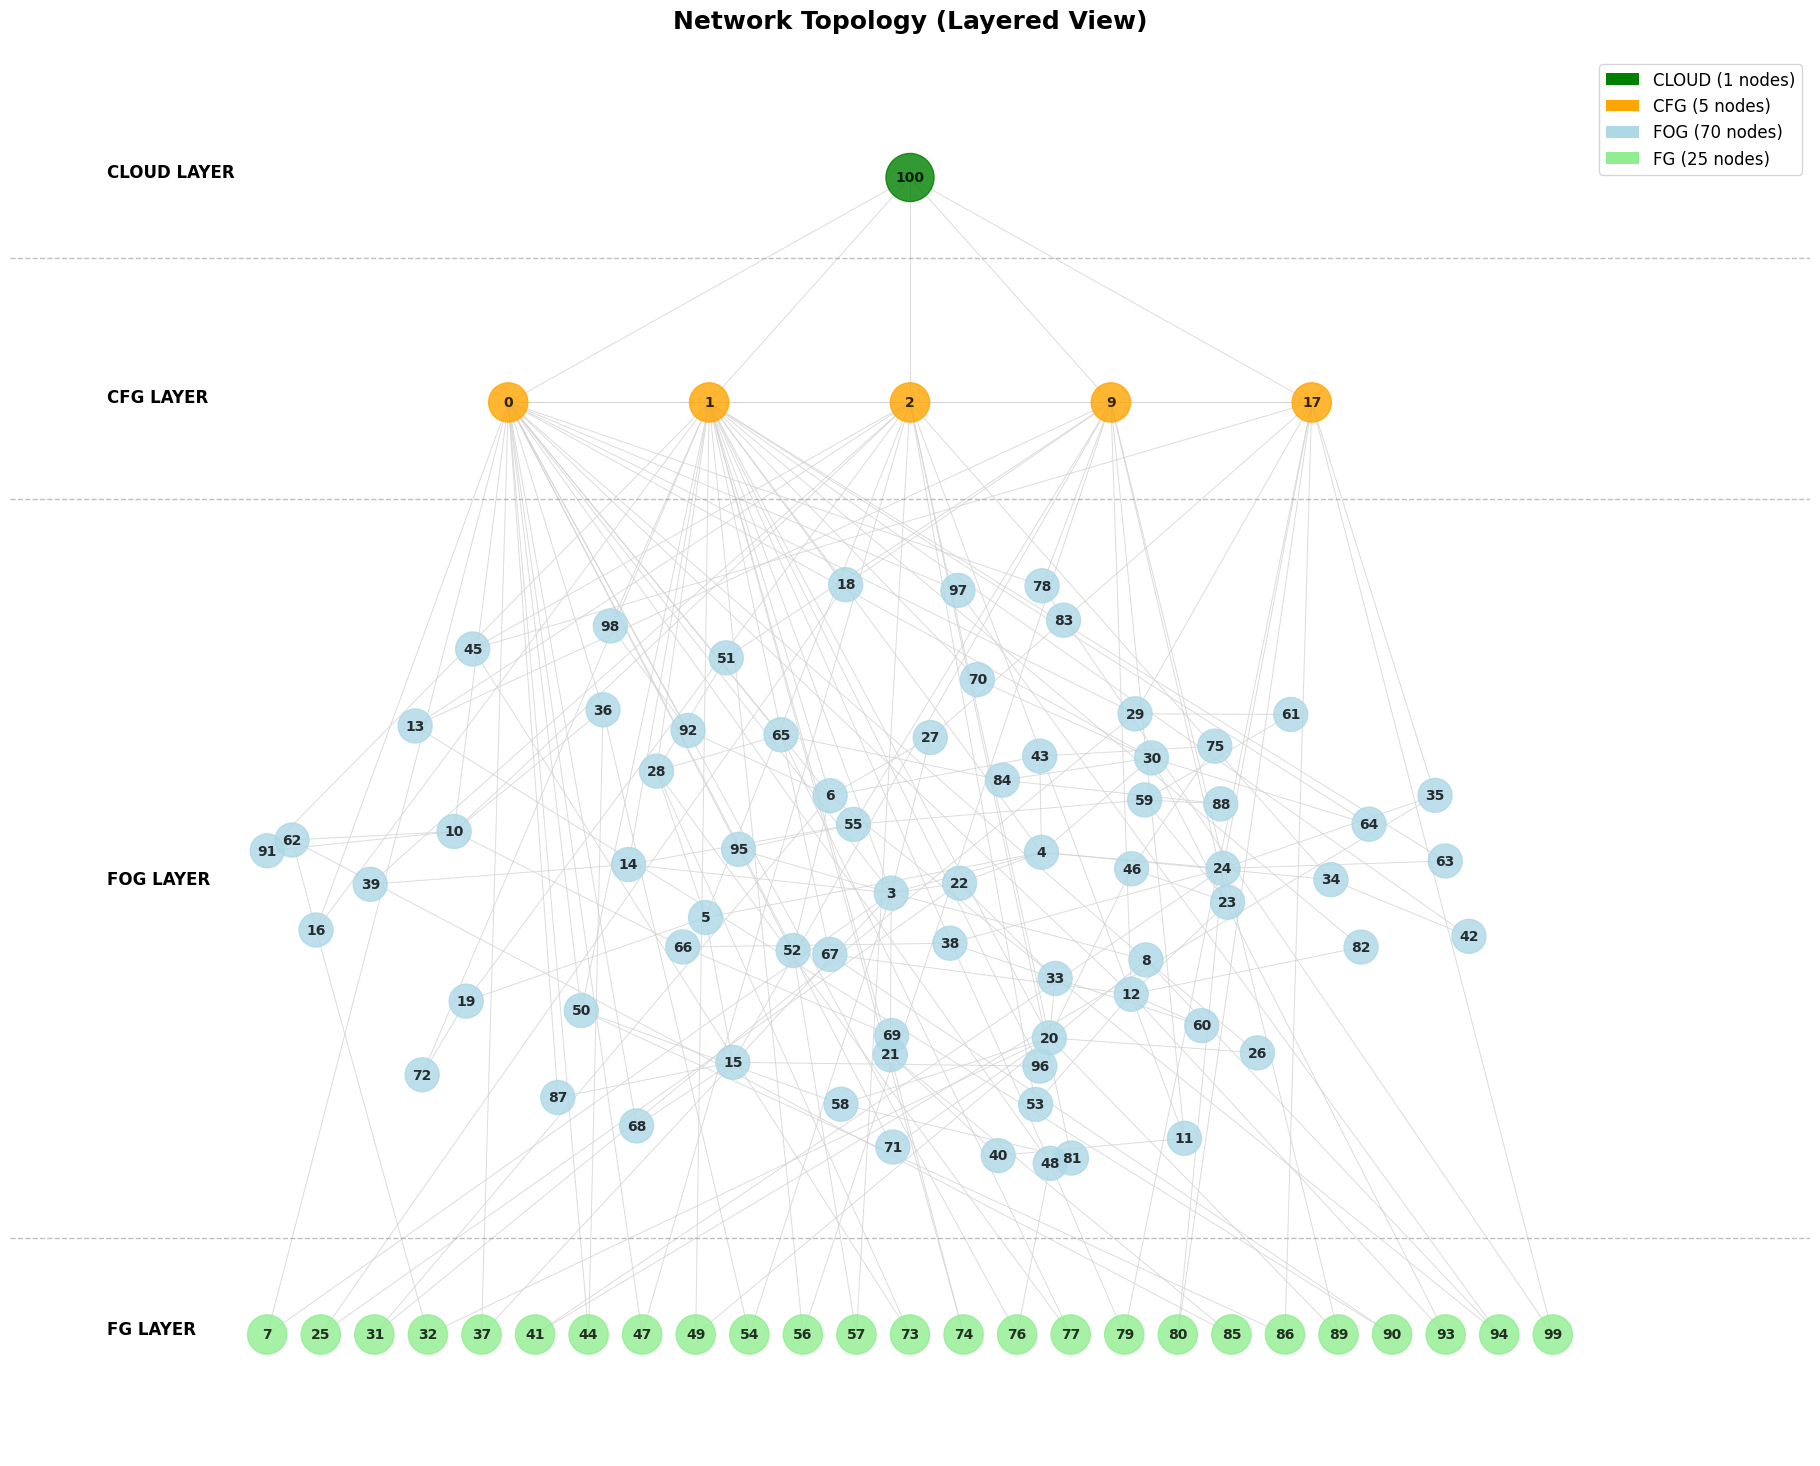

Gambar topologi tersimpan di: /Users/adhitya/Project/exp/analisis/1. network/topology_layers_20251024-141759.png

=== CLOUD CONNECTIONS ===
Cloud node 100 terhubung dengan 5 nodes: [0, 1, 2, 9, 17]

=== NODE DISTRIBUTION ===
CLOUD: 1 nodes
CFG:   5 nodes
FOG:   70 nodes
FG:    25 nodes
Total: 101 nodes


In [24]:
from matplotlib.patches import Patch

# --- folder & nama file output ---
save_dir = os.path.join(data_path, "analisis/1. network")
os.makedirs(save_dir, exist_ok=True)

ts = dt.datetime.now().strftime("%Y%m%d-%H%M%S")
out_path = os.path.join(save_dir, f"topology_layers_{ts}.png")

plt.figure(figsize=(18, 14))

# Warna per tipe node
color_map = {'CLOUD': 'green', 'CFG': 'orange', 'FOG': 'lightblue', 'FG': 'lightgreen'}

# Kategorisasi
cloud_nodes = [n for n in G.nodes() if G.nodes[n].get('type') == 'CLOUD']
cfg_nodes   = [n for n in G.nodes() if G.nodes[n].get('type') == 'CFG']
fog_nodes   = [n for n in G.nodes() if G.nodes[n].get('type') == 'FOG']
fg_nodes    = [n for n in G.nodes() if G.nodes[n].get('type') == 'FG']

print(f"CLOUD: {len(cloud_nodes)}, CFG: {len(cfg_nodes)}, FOG: {len(fog_nodes)}, FG: {len(fg_nodes)}")

# Layout manual berlapis
pos = {}

# Layer: CLOUD
y_cloud = 3.0
for i, node in enumerate(cloud_nodes):
    pos[node] = (0, y_cloud)

# Layer: CFG (spacing & centering)
y_cfg = 2.3
cfg_spacing = 2.5 / max(1, len(cfg_nodes) - 1) if len(cfg_nodes) > 1 else 0
for i, node in enumerate(cfg_nodes):
    x_cfg = -1.25 + i * cfg_spacing if len(cfg_nodes) > 1 else 0
    pos[node] = (x_cfg, y_cfg)

# Layer: FOG (spring layout dibatasi area)
if fog_nodes:
    fog_subgraph = G.subgraph(fog_nodes)
    fog_pos = nx.spring_layout(fog_subgraph, k=0.8, iterations=100, seed=42)
    y_fog, fog_width, fog_height = 0.8, 4.0, 2.0
    for node in fog_nodes:
        x_scaled = fog_pos[node][0] * fog_width/2
        y_scaled = fog_pos[node][1] * fog_height/2 + y_fog
        pos[node] = (x_scaled, y_scaled)

# Layer: FG
y_fg = -0.6
fg_spacing = 4.0 / max(1, len(fg_nodes) - 1) if len(fg_nodes) > 1 else 0
for i, node in enumerate(fg_nodes):
    x_fg = -2.0 + i * fg_spacing if len(fg_nodes) > 1 else 0
    pos[node] = (x_fg, y_fg)

# Warna & size
node_colors, node_sizes = [], []
for node in G.nodes():
    t = G.nodes[node].get('type', 'FOG')
    node_colors.append(color_map.get(t, 'gray'))
    size = 1200 if t == 'CLOUD' else 800 if t in ('CFG','FG') else 600
    node_sizes.append(size)

# Draw
nx.draw(
    G, pos,
    node_color=node_colors, node_size=node_sizes,
    with_labels=True, font_size=10, font_weight='bold', font_color='black',
    edge_color='lightgray', width=0.7, alpha=0.8
)

# Garis layer
plt.axhline(y=2.75, color='gray', linestyle='--', alpha=0.5, linewidth=1)
plt.axhline(y=2.0,  color='gray', linestyle='--', alpha=0.5, linewidth=1)
plt.axhline(y=-0.3, color='gray', linestyle='--', alpha=0.5, linewidth=1)

# Label layer
plt.text(-2.5, 3.0,  'CLOUD LAYER', fontsize=12, fontweight='bold', ha='left')
plt.text(-2.5, 2.3,  'CFG LAYER',   fontsize=12, fontweight='bold', ha='left')
plt.text(-2.5, 0.8,  'FOG LAYER',   fontsize=12, fontweight='bold', ha='left')
plt.text(-2.5, -0.6, 'FG LAYER',    fontsize=12, fontweight='bold', ha='left')

# Legend
legend_elements, legend_order = [], ['CLOUD','CFG','FOG','FG']
for t in legend_order:
    legend_elements.append(Patch(facecolor=color_map[t], label=f"{t} ({sum(G.nodes[n].get('type')==t for n in G.nodes())} nodes)"))
plt.legend(handles=legend_elements, loc='upper right', fontsize=12)

plt.title("Network Topology (Layered View)", fontsize=18, fontweight='bold', pad=20)
plt.axis('equal')
plt.tight_layout()

# --- SIMPAN SEBELUM SHOW ---
plt.savefig(out_path, dpi=200, bbox_inches='tight')  # <--- penting
plt.show()

print(f"Gambar topologi tersimpan di: {out_path}")

# Info tambahan
print("\n=== CLOUD CONNECTIONS ===")
if cloud_nodes:
    cloud_node = cloud_nodes[0]
    cloud_neighbors = list(G.neighbors(cloud_node))
    print(f"Cloud node {cloud_node} terhubung dengan {len(cloud_neighbors)} nodes: {cloud_neighbors}")

print("\n=== NODE DISTRIBUTION ===")
print(f"CLOUD: {len(cloud_nodes)} nodes")
print(f"CFG:   {len(cfg_nodes)} nodes")
print(f"FOG:   {len(fog_nodes)} nodes")
print(f"FG:    {len(fg_nodes)} nodes")
print(f"Total: {len(G.nodes())} nodes")

# 2. Application Definition

In [25]:
"""
Struktur dari appDefinition.json:
[
list of each application, each with:
    {
        id: int,
        name: string,
        deadline: int,  # deadline aplikasi (ms)
        module: [
            list of module, each with:
            {
                id: int,
                name: string,   # nama tiap module
                RAM: int,       # RAM yang dibutuhkan (MB)
                type: string,   # tipe dari module: MODULE, SOURCE, SINK
            }
        ],
        message: [
            list of message, each with:
            {
                id: int,
                name: string,
                s: string,         # nama module yang jadi sumber
                d: string,         # nama module yang jadi tujuan
                instructions: int  # jumlah instruksi yang diperlukan tiap request
                bytes: int,        # size dari message (bytes)
            }
        ],
        transmission: [
            list of transmission, each with:
            {
                module: string,         # nama module yang memproses
                message_in: string,     # nama message yang masuk
                message_out: string,    # nama message yang keluar
            }
        ]
    }
]
"""

'\nStruktur dari appDefinition.json:\n[\nlist of each application, each with:\n    {\n        id: int,\n        name: string,\n        deadline: int,  # deadline aplikasi (ms)\n        module: [\n            list of module, each with:\n            {\n                id: int,\n                name: string,   # nama tiap module\n                RAM: int,       # RAM yang dibutuhkan (MB)\n                type: string,   # tipe dari module: MODULE, SOURCE, SINK\n            }\n        ],\n        message: [\n            list of message, each with:\n            {\n                id: int,\n                name: string,\n                s: string,         # nama module yang jadi sumber\n                d: string,         # nama module yang jadi tujuan\n                instructions: int  # jumlah instruksi yang diperlukan tiap request\n                bytes: int,        # size dari message (bytes)\n            }\n        ],\n        transmission: [\n            list of transmission, each with

## 2.1 Apps, Messages, Module and Transmision

In [26]:
# --- EKSTRAK & SIMPAN (versi minimalis, tambah deadline) ---

modules_data, messages_data, transmissions_data = [], [], []

for app in app_definition:
    app_id       = app["id"]
    app_name     = app.get("name", str(app_id))
    app_deadline = app.get("deadline")  # <--- tambahkan ini

    # modules
    for m in app.get("module", []):
        modules_data.append({
            "app_id": app_id,
            "app_name": app_name,
            "app_deadline": app_deadline,           # <--- simpan deadline
            "module_id": m["id"],
            "module_name": m.get("name", str(m["id"])),
            "RAM": m.get("RAM", 0),
            "MIPS": m.get("MIPS", 0)
        })

    # messages
    for msg in app.get("message", []):
        src = msg.get("src") or msg.get("s") or msg.get("source") or msg.get("from")
        dst = msg.get("dst") or msg.get("d") or msg.get("destination") or msg.get("to")
        messages_data.append({
            "app_id": app_id,
            "app_name": app_name,
            "app_deadline": app_deadline,           # <--- simpan deadline
            "msg_id": msg.get("id"),
            "src": src,
            "dst": dst,
            "bytes": msg.get("bytes", 0),
            "instructions": msg.get("instructions", 0)
        })

    # transmissions
    for tr in app.get("transmission", []):
        transmissions_data.append({
            "app_id": app_id,
            "app_name": app_name,
            "app_deadline": app_deadline,           # <--- simpan deadline
            "module": tr.get("module"),
            "message_in": tr.get("message_in"),
            "message_out": tr.get("message_out")    # bisa None
        })

modules_df       = pd.DataFrame(modules_data)
messages_df      = pd.DataFrame(messages_data)
transmissions_df = pd.DataFrame(transmissions_data)

# --- SAVE ---
save_dir = os.path.join(data_path, "analisis/2. aplikasi")
os.makedirs(save_dir, exist_ok=True)

modules_df.to_csv(os.path.join(save_dir, "app_modules.csv"), index=False)
messages_df.to_csv(os.path.join(save_dir, "app_messages.csv"), index=False)
transmissions_df.to_csv(os.path.join(save_dir, "app_transmissions.csv"), index=False)

print(f"[OK] modules_df: {modules_df.shape}")
print(f"[OK] messages_df: {messages_df.shape}")
print(f"[OK] transmissions_df: {transmissions_df.shape}")
print("\nSemua file berhasil disimpan di folder:", save_dir)

summary = messages_df.groupby(["app_id","app_name","app_deadline"], dropna=False)\
    .agg(total_messages=("msg_id","count"),
         total_bytes=("bytes","sum"),
         total_instructions=("instructions","sum"))\
    .reset_index()

summary = summary.merge(
    modules_df.groupby(["app_id","app_name","app_deadline"], dropna=False)
              .agg(total_modules=("module_id","count"),
                   total_RAM=("RAM","sum"),
                   total_MIPS=("MIPS","sum")).reset_index(),
    on=["app_id","app_name","app_deadline"],
    how="outer"
)

summary.to_csv(os.path.join(save_dir,"app_summary.csv"), index=False)
print("[OK] app_summary.csv:", summary.shape)

print("=== RINGKASAN PER APLIKASI ===")
print(summary.sort_values("app_id").to_string(index=False))

[OK] modules_df: (195, 7)
[OK] messages_df: (195, 8)
[OK] transmissions_df: (261, 6)

Semua file berhasil disimpan di folder: /Users/adhitya/Project/exp/analisis/2. aplikasi
[OK] app_summary.csv: (40, 9)
=== RINGKASAN PER APLIKASI ===
 app_id app_name  app_deadline  total_messages  total_bytes  total_instructions  total_modules  total_RAM  total_MIPS
      0        0          5201               4     11454754              143899              4         18           0
      1        1          4518               3      8610434              126630              3         14           0
      2        2          3561               5     15106054              144834              5         17           0
      3        3          5121               3      9902634              143338              3          6           0
      4        4          3556               7     18101217              245584              7         24           0
      5        5          3997               7     181825

## 2.2 Visualisasi Messages

In [27]:
SHOW_EDGE_LABELS   = True           # True/False: tampilkan label edge
EDGE_LABEL_MODE    = "id"           # "id" | "brief" | "full"
SHOW_NODE_DETAILS  = False          # True = judul node berisi 'Modul\nRAM/MIPS'
FIGSIZE            = (11.5, 8.5)
H_SPACING, V_SPACING = 1.9, 1.7     # jarak antar-layer & antar-node per layer
CURVE              = 0.08           # kelengkungan edge (supaya tidak menimpa)

# ========= HELPERS =========
def get_src(msg):
    return msg.get("src") or msg.get("s") or msg.get("source") or msg.get("from")
def get_dst(msg):
    return msg.get("dst") or msg.get("d") or msg.get("destination") or msg.get("to")

def build_app_graph(app):
    """Bangun graf terarah: node=modul, edge=message."""
    G = nx.DiGraph()
    # nodes (modules)
    for m in app.get("module", []):
        name = m.get("name", str(m["id"]))
        G.add_node(
            name,
            id=m["id"],
            RAM=m.get("RAM", 0),
            MIPS=m.get("MIPS", 0),
        )
    # edges (messages)
    for msg in app.get("message", []):
        src, dst = get_src(msg), get_dst(msg)
        if src is None or dst is None:
            continue
        G.add_edge(
            src, dst,
            msg_id=msg.get("id", None),
            bytes=msg.get("bytes", None),
            instructions=msg.get("instructions", None),
        )
    return G

def layered_pos(G: nx.DiGraph):
    """
    Posisi berlapis (kiri->kanan) via topological_generations.
    Fallback: layering approx berbasis BFS dari entry jika graf bersiklus.
    """
    try:
        gens = list(nx.topological_generations(G))  # error jika ada siklus
    except nx.NetworkXUnfeasible:
        entries = [n for n in G.nodes if G.in_degree(n) == 0] or [next(iter(G.nodes))]
        layers, visited, frontier = [], set(), list(entries)
        while frontier:
            layer, next_frontier = [], []
            for u in frontier:
                if u in visited: 
                    continue
                visited.add(u); layer.append(u)
                for v in G.successors(u):
                    if v not in visited:
                        next_frontier.append(v)
            layers.append(layer)
            frontier = next_frontier
        gens = layers

    pos = {}
    for x, layer_nodes in enumerate(gens):
        n = len(layer_nodes)
        if n == 1:
            ys = [0.0]
        else:
            start = - (n - 1) * V_SPACING / 2.0
            ys = [start + i * V_SPACING for i in range(n)]
        for y, node in zip(ys, layer_nodes):
            pos[node] = (x * H_SPACING, y)
    return pos

def edge_label_text(d, mode="id"):
    if mode == "id":
        return f"id={d.get('msg_id')}" if d.get("msg_id") is not None else ""
    elif mode == "brief":
        parts = []
        if d.get("msg_id") is not None: parts.append(f"id={d['msg_id']}")
        if d.get("bytes") is not None:  parts.append(f"B={d['bytes']}")
        return ", ".join(parts)
    else:  # "full"
        parts = []
        if d.get("msg_id") is not None:       parts.append(f"id={d['msg_id']}")
        if d.get("bytes") is not None:        parts.append(f"bytes={d['bytes']}")
        if d.get("instructions") is not None: parts.append(f"instr={d['instructions']}")
        return ", ".join(parts)

def draw_app_graph(app, out_basepath):
    """Render satu aplikasi menjadi PNG; return path PNG."""
    G = build_app_graph(app)
    if len(G) == 0:
        return None

    pos = layered_pos(G)

    # Entry & sink detection
    entries = [n for n in G.nodes if G.in_degree(n) == 0]
    sinks   = [n for n in G.nodes if G.out_degree(n) == 0]

    # Node styles: warna by role, size ~ log(MIPS)
    node_colors, node_sizes, labels = [], [], {}
    for n, attrs in G.nodes(data=True):
        # warna
        if n in entries:
            color = "#90EE90"  # hijau muda (entry)
        elif n in sinks:
            color = "#FFB6C1"  # merah muda (sink)
        else:
            color = "#75B9FF"  # biru (intermediate)
        node_colors.append(color)

        # size
        mips = float(attrs.get("MIPS", 0) or 0)
        size = 950 if mips <= 0 else 950 + 0.6 * math.log10(1 + mips) * 750
        node_sizes.append(size)

        # label
        if SHOW_NODE_DETAILS:
            labels[n] = f"{n}\nRAM={attrs.get('RAM',0)}, MIPS={attrs.get('MIPS',0)}"
        else:
            labels[n] = n

    plt.figure(figsize=FIGSIZE)

    nx.draw_networkx_nodes(
        G, pos, node_color=node_colors, node_size=node_sizes,
        alpha=0.95, linewidths=1.0, edgecolors="black"
    )
    nx.draw_networkx_labels(G, pos, labels=labels, font_size=10, font_weight="bold")

    nx.draw_networkx_edges(
        G, pos, edge_color="#666666", arrows=True, width=1.7, alpha=0.95,
        connectionstyle=f"arc3,rad={CURVE}"
    )

    if SHOW_EDGE_LABELS:
        e_labels = { (u,v): edge_label_text(d, EDGE_LABEL_MODE) for u,v,d in G.edges(data=True) }
        nx.draw_networkx_edge_labels(
            G, pos, edge_labels=e_labels, font_size=8, rotate=False,
            bbox=dict(alpha=0.6, color="white")
        )

    # Legend
    legend_elems = [
        Patch(facecolor="#90EE90", edgecolor="black", label="Entry module (in_degree=0)"),
        Patch(facecolor="#FFB6C1", edgecolor="black", label="Sink module (out_degree=0)"),
        Patch(facecolor="#75B9FF", edgecolor="black", label="Intermediate"),
    ]
    plt.legend(handles=legend_elems, loc="lower left")
    plt.title(f"App #{app.get('id')} — {app.get('name', str(app.get('id')))}",
              fontsize=14, fontweight="bold", pad=10)
    plt.axis("off")
    plt.tight_layout()

    png_path = out_basepath + ".png"
    plt.savefig(png_path, dpi=220, bbox_inches="tight")
    plt.close()
    # plt.show()
    return png_path

save_dir = os.path.join(data_path, "analisis/2. aplikasi", "graph")
os.makedirs(save_dir, exist_ok=True)

# ========= RUN: render semua app =========
saved = []
for app in app_definition:
    app_id   = app["id"]
    app_name = app.get("name", str(app_id))
    safe = "".join(c if c.isalnum() or c in (" ", "_", "-") else "_" for c in app_name).strip()
    out_basepath = os.path.join(save_dir, f"app_{app_id}_{safe}")
    path = draw_app_graph(app, out_basepath)
    if path:
        saved.append((app_id, app_name, path))

print("Graf aplikasi tersimpan:")
for app_id, app_name, path in saved:
    print(f"- App #{app_id} ({app_name}): {path}")


Graf aplikasi tersimpan:
- App #0 (0): /Users/adhitya/Project/exp/analisis/2. aplikasi/graph/app_0_0.png
- App #1 (1): /Users/adhitya/Project/exp/analisis/2. aplikasi/graph/app_1_1.png
- App #2 (2): /Users/adhitya/Project/exp/analisis/2. aplikasi/graph/app_2_2.png
- App #3 (3): /Users/adhitya/Project/exp/analisis/2. aplikasi/graph/app_3_3.png
- App #4 (4): /Users/adhitya/Project/exp/analisis/2. aplikasi/graph/app_4_4.png
- App #5 (5): /Users/adhitya/Project/exp/analisis/2. aplikasi/graph/app_5_5.png
- App #6 (6): /Users/adhitya/Project/exp/analisis/2. aplikasi/graph/app_6_6.png
- App #7 (7): /Users/adhitya/Project/exp/analisis/2. aplikasi/graph/app_7_7.png
- App #8 (8): /Users/adhitya/Project/exp/analisis/2. aplikasi/graph/app_8_8.png
- App #9 (9): /Users/adhitya/Project/exp/analisis/2. aplikasi/graph/app_9_9.png
- App #10 (10): /Users/adhitya/Project/exp/analisis/2. aplikasi/graph/app_10_10.png
- App #11 (11): /Users/adhitya/Project/exp/analisis/2. aplikasi/graph/app_11_11.png
- App #

# 3. User Definition

In [28]:
"""
usersDefinition.json
 ├── app = "0"  ─────┐
 │                    ↓
 │              appDefinition.json
 │                ├── module[] (logika aplikasi)
 │                ├── message[] (alur komunikasi)
 │                └── transmission[] (urutan pesan)
 │
 └── id_resource = 7 ─┐
                      ↓
                networkDefinition.json
                  ├── entity[] (node specs)
                  └── link[] (koneksi antar node)
"""

'\nusersDefinition.json\n ├── app = "0"  ─────┐\n │                    ↓\n │              appDefinition.json\n │                ├── module[] (logika aplikasi)\n │                ├── message[] (alur komunikasi)\n │                └── transmission[] (urutan pesan)\n │\n └── id_resource = 7 ─┐\n                      ↓\n                networkDefinition.json\n                  ├── entity[] (node specs)\n                  └── link[] (koneksi antar node)\n'

## 3.1 Statisik User & Lambda

In [29]:
# Struktur: {"sources": [ {app, message, id_resource, lambda}, ... ]}
sources = users_def.get("sources", [])
users_df = pd.DataFrame(sources)

# Validasi kolom minimal
required_cols = {"app", "message", "id_resource", "lambda"}
missing = required_cols - set(users_df.columns)
if missing:
    raise ValueError(f"Kolom wajib hilang di usersDefinition.json: {missing}")

# Pastikan tipe
users_df["lambda"] = pd.to_numeric(users_df["lambda"], errors="coerce")  # ms
users_df["id_resource"] = pd.to_numeric(users_df["id_resource"], errors="coerce").astype("Int64")

# ================== REKAP DASAR ==================
total_users = len(users_df)
total_apps  = users_df["app"].nunique()
total_gw    = users_df["id_resource"].nunique()

print(f"Jumlah total user: {total_users}")
print(f"Jumlah aplikasi yang terhubung dengan user: {total_apps}")
print(f"Jumlah gateway (id_resource) yang dipakai user: {total_gw}")


Jumlah total user: 127
Jumlah aplikasi yang terhubung dengan user: 40
Jumlah gateway (id_resource) yang dipakai user: 25


In [30]:
# --- Normalisasi struktur ---
if isinstance(users_def, dict) and "sources" in users_def:
    sources = users_def["sources"]
elif isinstance(users_def, list):
    sources = users_def
else:
    raise ValueError("Struktur usersDefinition.json tidak dikenali (harus list atau dict['sources']).")

# --- Buat DataFrame ---
df_users = pd.DataFrame(sources)
df_users = df_users.rename(columns={
    "app": "app",
    "message": "message",
    "id_resource": "id_resource",
    "lambda": "lambda"
})

# --- Standarisasi tipe data ---
df_users["app"] = df_users["app"].astype(str)
df_users["message"] = df_users["message"].astype(str)
df_users["id_resource"] = pd.to_numeric(df_users["id_resource"], errors="coerce")
df_users["lambda"] = pd.to_numeric(df_users["lambda"], errors="coerce")

print("=== PREVIEW USERS ===")
print(df_users.head())
print("\nShape:", df_users.shape)

=== PREVIEW USERS ===
  app       message  id_resource  lambda
0   0  M.USER.APP.0           89     236
1   1  M.USER.APP.1           93     688
2   2  M.USER.APP.2           25     580
3   2  M.USER.APP.2           86     947
4   3  M.USER.APP.3           90     534

Shape: (127, 4)


In [31]:
# --- Ringkasan utama ---
by_app = df_users.groupby("app").size().reset_index(name="num_users")
by_node = df_users.groupby("id_resource").size().reset_index(name="num_users")
lambda_stats = df_users.groupby("app")["lambda"].agg(["count","mean","std","min","median","max"]).round(2).reset_index()

print("\n=== Jumlah user per app ===")
print(by_app.head(5).to_string(index=False))

print("\n=== Jumlah user per id_resource ===")
print(by_node.head(5).to_string(index=False))

print("\n=== Statistik lambda per app ===")
print(lambda_stats.head(5).to_string(index=False))


=== Jumlah user per app ===
app  num_users
  0          1
  1          1
 10          2
 11          2
 12          5

=== Jumlah user per id_resource ===
 id_resource  num_users
           7          5
          25          2
          31          9
          32          8
          37          5

=== Statistik lambda per app ===
app  count  mean    std  min  median  max
  0      1 236.0    NaN  236   236.0  236
  1      1 688.0    NaN  688   688.0  688
 10      2 602.0 181.02  474   602.0  730
 11      2 480.0  16.97  468   480.0  492
 12      5 533.4 112.59  427   480.0  656


In [32]:
# ================== DEFINISI GATEWAY: HANYA FG ==================
entities_df = pd.DataFrame(network_definition["entity"])

entities_df["type"] = entities_df["type"].astype(str).str.upper()
GATEWAY_TYPES = {"FG"}            # <--- penting: hanya FG dianggap gateway
gateway_df = entities_df[entities_df["type"].isin(GATEWAY_TYPES)].copy()

# Daftar FG (defined), used FG (muncul di users), dan unused FG
fg_ids = sorted(set(gateway_df["id"].astype(int).tolist()))
used_fg_ids = sorted(set(df_users["id_resource"].dropna().astype(int).tolist()) & set(fg_ids))
unused_fg_ids = [g for g in fg_ids if g not in used_fg_ids]

print("=== FG gateways digunakan user (ID) ===")
print(used_fg_ids)
print("\n=== FG gateways TIDAK digunakan user (ID) ===")
print(unused_fg_ids)

# Matrix gateway(FG) x app (untuk stacked bar)
gw_app = df_users.groupby(["id_resource", "app"]).size().reset_index(name="num_users")

# --- (Opsional) Simpan ke CSV ---
save_dir = os.path.join(data_path, "analisis/3. users")
os.makedirs(save_dir, exist_ok=True)

df_users.to_csv(os.path.join(save_dir, "users.csv"), index=False)
by_app.to_csv(os.path.join(save_dir, "users_by_app.csv"), index=False)
by_node.to_csv(os.path.join(save_dir, "users_by_node.csv"), index=False)
lambda_stats.to_csv(os.path.join(save_dir, "lambda_stats.csv"), index=False)
gw_app.to_csv(os.path.join(save_dir, "users_gateway_app_matrix.csv"), index=False)

print(f"\n[OK] Semua file users berhasil disimpan ke folder: {save_dir}")

=== FG gateways digunakan user (ID) ===
[7, 25, 31, 32, 37, 41, 44, 47, 49, 54, 56, 57, 73, 74, 76, 77, 79, 80, 85, 86, 89, 90, 93, 94, 99]

=== FG gateways TIDAK digunakan user (ID) ===
[]

[OK] Semua file users berhasil disimpan ke folder: /Users/adhitya/Project/exp/analisis/3. users


## 3.2 Visualisasi 

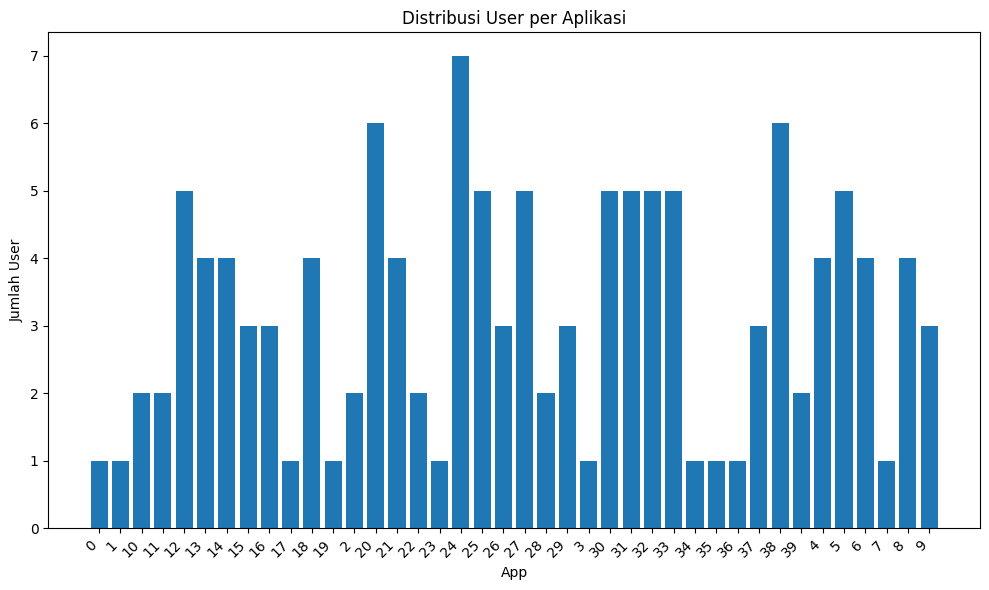

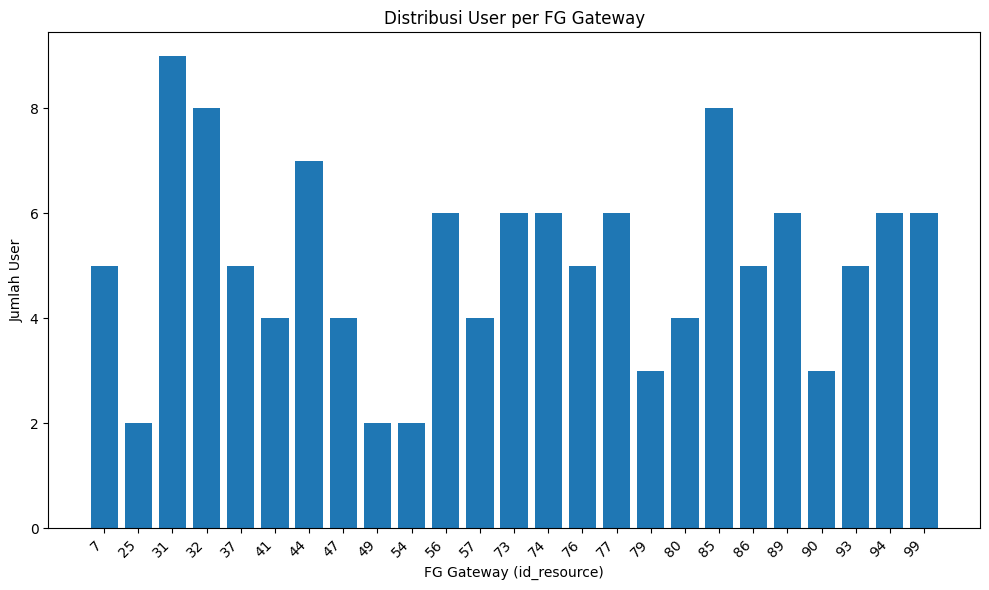

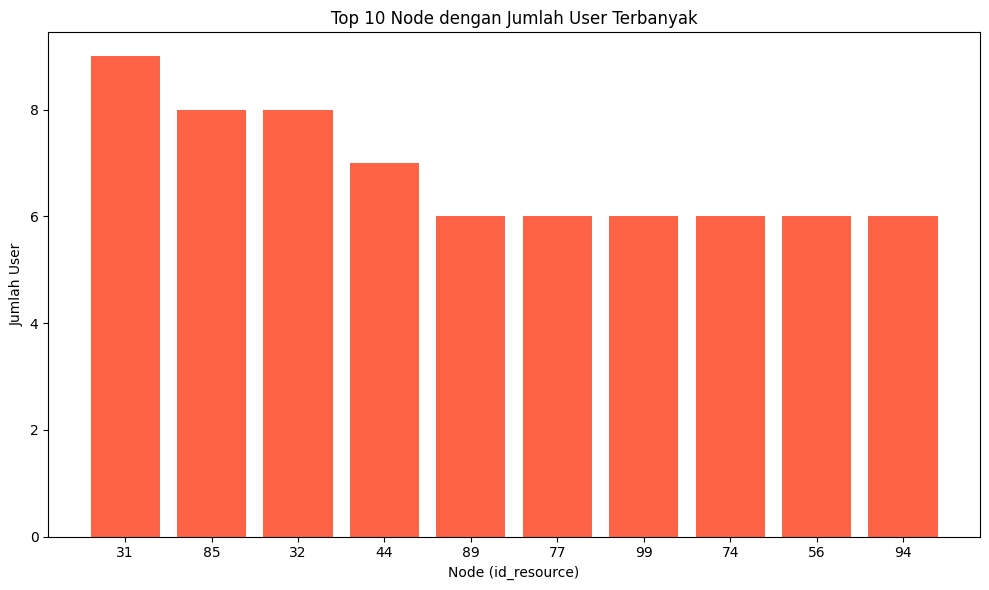

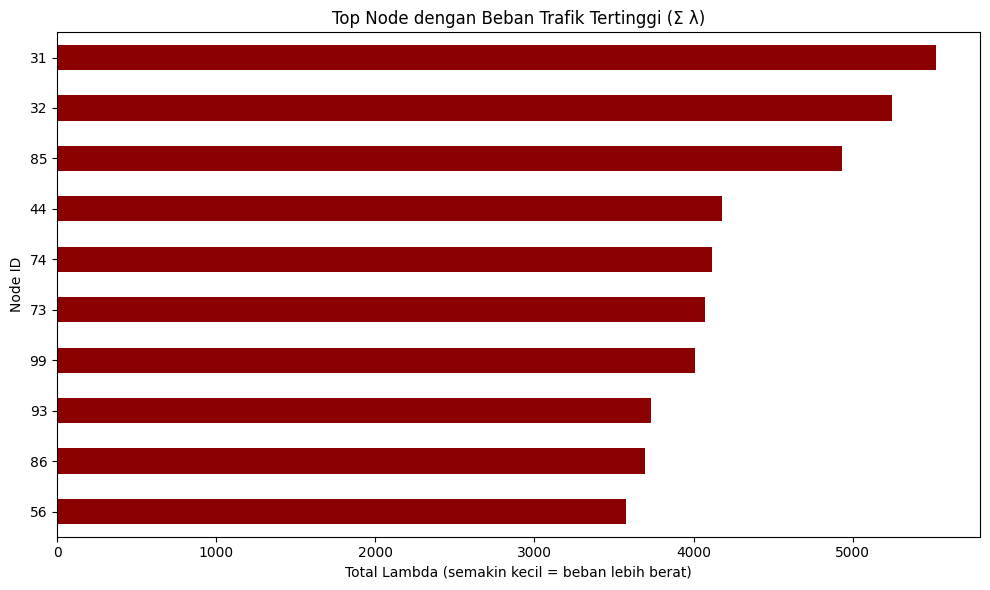

In [33]:
# 0) siapkan folder graf
graph_dir = os.path.join(save_dir, "graph")
os.makedirs(graph_dir, exist_ok=True)

# 1) jumlah user per aplikasi
app_summary = (
    df_users
    .groupby("app", dropna=False)
    .size()
    .reset_index(name="num_users")     # <--- pastikan kolom 'num_users' ada
    .sort_values("app")
)

# 2) jumlah user per FG gateway (jika kamu punya df_users_enriched dengan node_type)
#    kalau tidak ada node_type, baris filter bisa diabaikan
if "node_type" in df_users.columns:
    df_fg = df_users[df_users["node_type"] == "FG"].copy()
else:
    df_fg = df_users.copy()

gw_summary = (
    df_fg
    .groupby("id_resource", dropna=False)
    .size()
    .reset_index(name="num_users")     # <--- pastikan kolom 'num_users' ada
    .sort_values("id_resource")
)

# 3) komposisi user per FG gateway menurut app (stacked)
gw_app = (
    df_fg
    .groupby(["id_resource", "app"], dropna=False)
    .size()
    .reset_index(name="num_users")     # <--- pastikan kolom 'num_users' ada
    .sort_values(["id_resource", "app"])
)

# ====== GRAFIK BAR (tanpa heatmap) ======

# A) jumlah user per aplikasi
plt.figure(figsize=(10,6))
plt.bar(app_summary["app"].astype(str), app_summary["num_users"])
plt.xlabel("App"); plt.ylabel("Jumlah User")
plt.title("Distribusi User per Aplikasi")
plt.xticks(rotation=45, ha="right"); plt.tight_layout()
p1 = os.path.join(graph_dir, "users_per_app.png")
plt.savefig(p1, dpi=160, bbox_inches="tight"); plt.show()

# B) jumlah user per FG gateway
plt.figure(figsize=(10,6))
plt.bar(gw_summary["id_resource"].astype(str), gw_summary["num_users"])
plt.xlabel("FG Gateway (id_resource)"); plt.ylabel("Jumlah User")
plt.title("Distribusi User per FG Gateway")
plt.xticks(rotation=45, ha="right"); plt.tight_layout()
p2 = os.path.join(graph_dir, "users_per_fg_gateway.png")
plt.savefig(p2, dpi=160, bbox_inches="tight"); plt.show()

# C) Top Node
plt.figure(figsize=(10,6))
top_nodes = df_users["id_resource"].value_counts().head(10)
plt.bar(top_nodes.index.astype(str), top_nodes.values, color="tomato")
plt.title("Top 10 Node dengan Jumlah User Terbanyak")
plt.xlabel("Node (id_resource)")
plt.ylabel("Jumlah User")
plt.tight_layout()
p3 = os.path.join(graph_dir, "top_node-users.png")
plt.savefig(p3, dpi=160, bbox_inches="tight"); plt.show()

lambda_sum = df_users.groupby("id_resource")["lambda"].sum().sort_values(ascending=True)
plt.figure(figsize=(10,6))
lambda_sum.tail(10).plot(kind="barh", color="darkred")
plt.title("Top Node dengan Beban Trafik Tertinggi (Σ λ)")
plt.xlabel("Total Lambda (semakin kecil = beban lebih berat)")
plt.ylabel("Node ID")
plt.tight_layout()
p4 = os.path.join(graph_dir, "top_node-lambda.png")
plt.savefig(p4, dpi=160, bbox_inches="tight"); plt.show()


# 4. Algoritma Placement

## 4.1 Data Placement

In [34]:
from pathlib import Path

def export_allocation_csv(alloc_json: dict,
                          algo_name: str,
                          network_definition: dict,
                          out_root: str):
    """
    Buat paket CSV untuk satu algoritma allocation.
    Output disimpan di: {out_root}/{algo_name}/

    CSV yang dihasilkan:
      1) 1_join_allocation_with_nodes.csv
      2) 2_app_solution.csv                 (visualisasi penyelesaian/solusi per app)  
      3) 3_layer_distribution.csv           (distribusi modul berdasarkan layer)     
      4) 4_node_hotspots.csv                (top node/module density)
    """
    # ---------- 0) normalisasi input ----------
    # nodes
    df_nodes = pd.DataFrame(network_definition["entity"])[["id", "type", "RAM", "IPT", "TB"]]
    df_nodes = df_nodes.rename(columns={"id": "id_resource", "type": "node_type"})

    # allocation raw
    key = "initialAllocation"
    if key not in alloc_json or not isinstance(alloc_json[key], list):
        raise ValueError(f"Kunci '{key}' tidak ditemukan/invalid di alloc_json.")
    df_alloc_raw = pd.DataFrame(alloc_json[key]).copy()

    # jaga-jaga: pastikan kolom minimal ada
    for col in ["app", "module_name", "id_resource"]:
        if col not in df_alloc_raw.columns:
            df_alloc_raw[col] = None

    # normalisasi tipe
    df_alloc_raw["app"] = df_alloc_raw["app"].astype(str)
    df_alloc_raw["module_name"] = df_alloc_raw["module_name"].astype(str)
    df_alloc_raw["id_resource"] = pd.to_numeric(df_alloc_raw["id_resource"], errors="coerce")

    out_dir = Path(out_root) / algo_name
    out_dir.mkdir(parents=True, exist_ok=True)

    # ---------- 1) Join allocation + network definition ----------
    df_join = df_alloc_raw.merge(df_nodes, on="id_resource", how="left")
    p1 = out_dir / "1_join_allocation_with_nodes.csv"
    df_join.to_csv(p1, index=False)

    # ---------- 2) Visualisasi penyelesaian per app ----------
    # interpretasi: solusi per app = daftar modul + node penempatannya (beserta layer/type)
    df_app_solution = (
        df_join
        .sort_values(["app", "module_name", "id_resource"])
        [["app", "module_name", "id_resource", "node_type", "RAM", "IPT", "TB"]]
        .reset_index(drop=True)
    )
    p2 = out_dir / "2_app_solution.csv"
    df_app_solution.to_csv(p2, index=False)

    # ---------- 3) Distribusi modul berdasarkan layer ----------
    df_layer_dist = (
        df_join.groupby("node_type")
               .size()
               .reset_index(name="num_modules")
               .sort_values("num_modules", ascending=False)
    )
    p3 = out_dir / "3_layer_distribution.csv"
    df_layer_dist.to_csv(p3, index=False)

    # ---------- 4) Node hotspots ----------
    df_node_hotspots = (
        df_join.groupby(["id_resource", "node_type"])
               .size()
               .reset_index(name="num_modules")
               .sort_values("num_modules", ascending=False)
    )
    p4 = out_dir / "4_node_hotspots.csv"
    df_node_hotspots.to_csv(p4, index=False)

    print(f"[{algo_name}] DONE")
    print("  ", p1)
    print("  ", p2)
    print("  ", p3)
    print("  ", p4)
    
# ==================== CONTOH PEMAKAIAN ====================

with open(data_path + 'data/allocDefinitionILP.json', 'r') as file:
    alloc_ilp = json.load(file)

# 1) untuk ILP
export_allocation_csv(
    alloc_json=alloc_ilp,
    algo_name="ILP",
    network_definition=network_definition,
    out_root=os.path.join(data_path, "analisis/4. allocation_csv")
)

# 2) kalau nanti ada algoritma lain:
# with open(data_path + 'data/allocDefinitionMOLP.json', 'r') as f:
#     alloc_molp = json.load(f)
# export_allocation(alloc_molp, "MOLP", network_definition, os.path.join(data_path, "4. allocation"))

# with open(data_path + 'data/allocDefinitionHeuristic.json', 'r') as f:
#     alloc_heur = json.load(f)
# export_allocation(alloc_heur, "Heuristic", network_definition, os.path.join(data_path, "4. allocation"))


[ILP] DONE
   /Users/adhitya/Project/exp/analisis/4. allocation_csv/ILP/1_join_allocation_with_nodes.csv
   /Users/adhitya/Project/exp/analisis/4. allocation_csv/ILP/2_app_solution.csv
   /Users/adhitya/Project/exp/analisis/4. allocation_csv/ILP/3_layer_distribution.csv
   /Users/adhitya/Project/exp/analisis/4. allocation_csv/ILP/4_node_hotspots.csv


## 4.2 Visualisasi Placement

In [35]:
# ============== KONFIG VISUAL ==============
SHOW_EDGE_LABELS   = True
EDGE_LABEL_MODE    = "id"           # "id" | "brief" | "full"
SHOW_NODE_DETAILS  = False
FIGSIZE            = (11.5, 8.5)
H_SPACING, V_SPACING = 1.9, 1.7
CURVE              = 0.08

LAYER_RING = {
    "CLOUD": "#2ecc71",  # hijau
    "CFG":   "#f39c12",  # oranye
    "FOG":   "#3498db",  # biru
    "FG":    "#9b59b6",  # ungu
    None:    "#7f8c8d"   # abu (unknown)
}

# ============== HELPERS GRAF APLIKASI ==============
def get_src(msg):
    return msg.get("src") or msg.get("s") or msg.get("source") or msg.get("from")
def get_dst(msg):
    return msg.get("dst") or msg.get("d") or msg.get("destination") or msg.get("to")

def build_app_graph(app):
    G = nx.DiGraph()
    for m in app.get("module", []):
        name = m.get("name", str(m["id"]))
        G.add_node(name, id=m["id"], RAM=m.get("RAM", 0), MIPS=m.get("MIPS", 0))
    for msg in app.get("message", []):
        src, dst = get_src(msg), get_dst(msg)
        if src is None or dst is None: 
            continue
        G.add_edge(src, dst,
                   msg_id=msg.get("id"),
                   bytes=msg.get("bytes"),
                   instructions=msg.get("instructions"))
    return G

def layered_pos(G: nx.DiGraph):
    try:
        gens = list(nx.topological_generations(G))
    except nx.NetworkXUnfeasible:
        entries = [n for n in G.nodes if G.in_degree(n) == 0] or [next(iter(G.nodes))]
        layers, visited, frontier = [], set(), list(entries)
        while frontier:
            layer, next_frontier = [], []
            for u in frontier:
                if u in visited: 
                    continue
                visited.add(u); layer.append(u)
                for v in G.successors(u):
                    if v not in visited:
                        next_frontier.append(v)
            layers.append(layer)
            frontier = next_frontier
        gens = layers

    pos = {}
    for x, layer_nodes in enumerate(gens):
        n = len(layer_nodes)
        ys = [0.0] if n == 1 else [-(n-1)*V_SPACING/2 + i*V_SPACING for i in range(n)]
        for y, node in zip(ys, layer_nodes):
            pos[node] = (x * H_SPACING, y)
    return pos

def edge_label_text(d, mode="id"):
    if mode == "id":
        return f"id={d.get('msg_id')}" if d.get("msg_id") is not None else ""
    elif mode == "brief":
        parts = []
        if d.get("msg_id") is not None: parts.append(f"id={d['msg_id']}")
        if d.get("bytes") is not None:  parts.append(f"B={d['bytes']}")
        return ", ".join(parts)
    else:
        parts = []
        if d.get("msg_id") is not None:       parts.append(f"id={d['msg_id']}")
        if d.get("bytes") is not None:        parts.append(f"bytes={d['bytes']}")
        if d.get("instructions") is not None: parts.append(f"instr={d['instructions']}")
        return ", ".join(parts)


# ============== VISUALISASI APP_SOLUTION DI FOLDER YANG SAMA ==============
def build_placement_lookup_from_json(alloc_json: dict, network_definition: dict):
    # nodes (ambil layer/type)
    df_nodes = pd.DataFrame(network_definition["entity"])[["id","type"]]
    df_nodes = df_nodes.rename(columns={"id":"id_resource","type":"node_type"})

    # allocation raw
    df_alloc = pd.DataFrame(alloc_json["initialAllocation"]).copy()
    df_alloc["app"] = df_alloc["app"].astype(str)
    df_alloc = df_alloc.merge(df_nodes, on="id_resource", how="left")

    mp = (
        df_alloc.groupby(["app","module_name"])
                .agg(id_list=("id_resource", lambda s: tuple(s)),
                     type_list=("node_type",  lambda s: tuple(s)))
                .reset_index()
    )
    return {
        (row["app"], row["module_name"]): {
            "id_list": row["id_list"], "type_list": row["type_list"]
        }
        for _, row in mp.iterrows()
    }

def draw_app_graph_with_placement(app: dict, algo_name: str, placement_lookup: dict, out_graph_dir: str):
    """Render 1 aplikasi menjadi PNG; simpan ke out_graph_dir."""
    G = build_app_graph(app)
    if len(G) == 0:
        return None

    os.makedirs(out_graph_dir, exist_ok=True)
    app_id   = app["id"]
    app_name = app.get("name", str(app_id))
    safe     = "".join(c if c.isalnum() or c in (" ", "_", "-") else "_" for c in app_name).strip()
    out_basepath = os.path.join(out_graph_dir, f"app_{app_id}_{safe}")

    pos = layered_pos(G)
    entries = [n for n in G.nodes if G.in_degree(n) == 0]
    sinks   = [n for n in G.nodes if G.out_degree(n) == 0]

    node_facecolors, node_edgecolors, node_sizes, labels = [], [], [], {}
    app_id_str = str(app_id)

    for n, attrs in G.nodes(data=True):
        # isi node by role
        face = "#90EE90" if n in entries else "#FFB6C1" if n in sinks else "#75B9FF"
        node_facecolors.append(face)

        # size ~ log(MIPS)
        mips = float(attrs.get("MIPS", 0) or 0)
        size = 950 if mips <= 0 else 950 + 0.6 * math.log10(1 + mips) * 750
        node_sizes.append(size)

        info = placement_lookup.get((app_id_str, n), None)
        if info and len(info["type_list"]) > 0:
            types = [t if pd.notna(t) else None for t in info["type_list"]]
            mode_layer = max(set(types), key=types.count) if len(types) > 0 else None
            ring = LAYER_RING.get(mode_layer, LAYER_RING[None])
            node_edgecolors.append(ring)
            id_list = info["id_list"]
            suffix = f"\n@{list(dict.fromkeys(id_list))} / \n{list(dict.fromkeys(types))}" \
                     if len(set(id_list)) > 1 or len(set(types)) > 1 \
                     else f"\n@{id_list[0]} / {mode_layer}"
        else:
            node_edgecolors.append(LAYER_RING[None])
            suffix = "\n@– / –"

        labels[n] = (f"{n}{suffix}" if not SHOW_NODE_DETAILS
                     else f"{n}\nRAM={attrs.get('RAM',0)}, MIPS={attrs.get('MIPS',0)}")

    # draw
    plt.figure(figsize=FIGSIZE)
    nx.draw_networkx_nodes(G, pos, node_color=node_facecolors, node_size=node_sizes,
                           linewidths=2.2, edgecolors=node_edgecolors, alpha=0.96)
    nx.draw_networkx_labels(G, pos, labels=labels, font_size=10, font_weight="bold")
    nx.draw_networkx_edges(G, pos, edge_color="#666666", arrows=True, width=1.7,
                           alpha=0.95, connectionstyle=f"arc3,rad={CURVE}")

    if SHOW_EDGE_LABELS:
        e_labels = {(u,v): edge_label_text(d, EDGE_LABEL_MODE) for u,v,d in G.edges(data=True)}
        nx.draw_networkx_edge_labels(G, pos, edge_labels=e_labels, font_size=8, rotate=False,
                                     bbox=dict(alpha=0.6, color="white"))

    legend_nodes = [
        Patch(facecolor="#90EE90", edgecolor="black", label="Entry"),
        Patch(facecolor="#FFB6C1", edgecolor="black", label="Sink"),
        Patch(facecolor="#75B9FF", edgecolor="black", label="Intermediate"),
    ]
    legend_rings = [Patch(facecolor="white", edgecolor=c, label=f"{layer}")
                    for layer, c in LAYER_RING.items() if layer is not None]
    plt.legend(handles=legend_nodes + legend_rings, loc="lower left", fontsize=9)

    title = f"App #{app_id} — {app_name}  |  Placement: {algo_name}"
    plt.title(title, fontsize=14, fontweight="bold", pad=10)
    plt.axis("off")
    plt.tight_layout()

    png_path = out_basepath + f"__{algo_name}.png"
    plt.savefig(png_path, dpi=220, bbox_inches="tight")
    plt.close()
    return png_path

# ============== PIPELINE KOMBINASI: EKSPOR CSV + VISUAL ==============
def process_allocation(algo_name: str,
                       alloc_json: dict,
                       network_definition: dict,
                       app_definition: list,
                       data_path: str):
    """
    Simpan visualisasi app_solution ke:
      {data_path}/analisis/4. allocation_csv/{algo_name}/graph/
    Return: list path PNG yang dibuat.
    """
 
    graph_dir = os.path.join(data_path, "analisis/4. allocation_csv", algo_name, "graph")
    os.makedirs(graph_dir, exist_ok=True)

    # build placement lookup dari file join (agar konsisten)
    placement_lookup = build_placement_lookup_from_json(alloc_json, network_definition)
    
    saved = []
    for app in app_definition:
        path = draw_app_graph_with_placement(app, algo_name, placement_lookup, graph_dir)
        if path:
            saved.append((app["id"], app.get("name", str(app["id"])), path))

    print(f"[{algo_name}] Graf aplikasi tersimpan:")
    for app_id, app_name, path in saved:
        print(f"- App #{app_id} ({app_name}): {path}")


# ============== CONTOH PEMAKAIAN ==============
# Asumsi variabel sudah ada:
#   data_path, network_definition, app_definition, alloc_ilp

process_allocation(
    algo_name="ILP",
    alloc_json=alloc_ilp,
    network_definition=network_definition,
    app_definition=app_definition,
    data_path=data_path
)

# Kalau ada algoritma lain, tinggal panggil ulang:
# process_allocation("MOLP", alloc_molp, network_definition, app_definition, data_path)
# process_allocation("Heuristic", alloc_heur, network_definition, app_definition, data_path)


[ILP] Graf aplikasi tersimpan:
- App #0 (0): /Users/adhitya/Project/exp/analisis/4. allocation_csv/ILP/graph/app_0_0__ILP.png
- App #1 (1): /Users/adhitya/Project/exp/analisis/4. allocation_csv/ILP/graph/app_1_1__ILP.png
- App #2 (2): /Users/adhitya/Project/exp/analisis/4. allocation_csv/ILP/graph/app_2_2__ILP.png
- App #3 (3): /Users/adhitya/Project/exp/analisis/4. allocation_csv/ILP/graph/app_3_3__ILP.png
- App #4 (4): /Users/adhitya/Project/exp/analisis/4. allocation_csv/ILP/graph/app_4_4__ILP.png
- App #5 (5): /Users/adhitya/Project/exp/analisis/4. allocation_csv/ILP/graph/app_5_5__ILP.png
- App #6 (6): /Users/adhitya/Project/exp/analisis/4. allocation_csv/ILP/graph/app_6_6__ILP.png
- App #7 (7): /Users/adhitya/Project/exp/analisis/4. allocation_csv/ILP/graph/app_7_7__ILP.png
- App #8 (8): /Users/adhitya/Project/exp/analisis/4. allocation_csv/ILP/graph/app_8_8__ILP.png
- App #9 (9): /Users/adhitya/Project/exp/analisis/4. allocation_csv/ILP/graph/app_9_9__ILP.png
- App #10 (10): /Us

# 5. Analisis Hasil

## ILP

### 5.1 Metriks Evaluasi

In [36]:
# Load CSV
df_app = pd.read_csv(data_path +'results/results_ILP_1000000.csv')
df_link = pd.read_csv(data_path +'results/results_ILP_1000000_link.csv')

# Entities dataframe (id, type) untuk mapping layer node
entities_df = pd.DataFrame(network_definition["entity"])
entities_df["type"] = entities_df["type"].astype(str).str.upper()
entities_df = entities_df.rename(columns={"id":"id_resource", "type":"node_type"})
entities_df = entities_df[["id_resource","node_type","RAM","IPT","TB"]]

print("=== df_app columns ===")
print(df_app.columns.tolist())
print("\n=== df_link columns ===")
print(df_link.columns.tolist())
print("\n=== df_link columns ===")
print(entities_df.columns.tolist())

display(df_app.head(3))
display(df_link.head(3))
display(entities_df.head(3))

FileNotFoundError: [Errno 2] No such file or directory: '/Users/adhitya/Project/exp/results/results_ILP_1000000.csv'

### 5.2 Result Algoritma

In [ ]:
# --- Pastikan kolom waktu dalam tipe numerik ---
for col in ["time_in", "time_out", "time_emit", "time_reception"]:
    df_app[col] = pd.to_numeric(df_app[col], errors="coerce")

# --- Buat kolom dasar waktu turunan ---
df_app["E2E_latency"] = df_app["time_reception"] - df_app["time_emit"]
df_app["processing_time"] = df_app["time_out"] - df_app["time_in"]
df_app["network_delay"] = (df_app["time_in"] - df_app["time_emit"]).abs()

# --- Hitung End-to-End Latency (E2E) ---
e2e_summary = (
    df_app.groupby("app")["E2E_latency"]
    .mean()
    .reset_index()
    .rename(columns={"E2E_latency": "avg_E2E_latency"})
)
print("=== Rata-rata End-to-End Latency per App ===")
print(e2e_summary)

# --- Hitung Processing Time ---
proc_summary = (
    df_app.groupby(["app", "module"])["processing_time"]
    .mean()
    .reset_index()
    .rename(columns={"processing_time": "avg_processing_time"})
)
print("\n=== Rata-rata Processing Time per Modul ===")
print(proc_summary.head(10))

# --- Hitung Network Delay (Transmission Delay) ---
netdelay_summary = (
    df_app.groupby(["TOPO.src", "TOPO.dst"])["network_delay"]
    .mean()
    .reset_index()
    .rename(columns={"network_delay": "avg_network_delay"})
)
print("\n=== Network Delay antar Node ===")
print(netdelay_summary.head(10))

# --- Hitung Response Time per App) ---
response_time = (
    df_app.groupby("app")["E2E_latency"]
    .mean()
    .reset_index()
    .rename(columns={"E2E_latency": "avg_response_time"})
)
print("\n=== Response Time per App ===")
print(response_time)

# --- Hitung Layer Performance ---
# --- join layer info ke df_app ---
df_app_layer = df_app.merge(
    entities_df.rename(columns={"id_resource": "TOPO.dst"}),
    how="left",
    on="TOPO.dst"
)

layer_perf = (
    df_app_layer.groupby("node_type")["E2E_latency"]
    .mean()
    .reset_index()
    .rename(columns={"E2E_latency": "avg_E2E_latency"})
    .sort_values("avg_E2E_latency")
)

print("\n=== Rata-rata Latency per Layer (CLOUD/CFG/FOG/FG) ===")
print(layer_perf)


# --- (Ganti nama Algoritmanya) Simpan ke CSV ---
save_dir = os.path.join(data_path, "analisis/5. evaluasi/ILP")
os.makedirs(save_dir, exist_ok=True)

e2e_summary.to_csv(os.path.join(save_dir, "E2E_Latency.csv"), index=False)
proc_summary.to_csv(os.path.join(save_dir, "Processing_Time.csv"), index=False)
netdelay_summary.to_csv(os.path.join(save_dir, "Network_Delay.csv"), index=False)
response_time.to_csv(os.path.join(save_dir, "Response_Time_per_App.csv"), index=False)
layer_perf.to_csv(os.path.join(save_dir, "Layer_Performance.csv"), index=False)

# | Metrik                    | Tujuan                       | Tolok Ukur Efisiensi ILP                         |
# | ------------------------- | ---------------------------- | ------------------------------------------------ |
# | **E2E Latency**           | Waktu total perjalanan pesan | Semakin kecil → semakin baik placement           |
# | **Processing Time**       | Waktu eksekusi modul         | Harus sebanding dengan kapasitas IPT node        |
# | **Network Delay**         | Waktu transmisi antar node   | Semakin kecil → semakin efisien routing          |
# | **Response Time per App** | Kinerja aplikasi global      | Nilai rata-rata per app turun signifikan         |
# | **Layer Performance**     | Kinerja tiap layer           | Delay FG/FOG < CFG/CLOUD menunjukkan ILP optimal |

=== Rata-rata End-to-End Latency per App ===
    app  avg_E2E_latency
0     0        26.319935
1     1        39.462833
2     2        26.086873
3     3        46.526837
4     4        16.606531
5     5        16.309683
6     6        46.948695
7     7        21.223273
8     8        50.030487
9     9        20.209096
10   10        63.559391
11   11        18.600410
12   12        54.367994
13   13        13.421777
14   14        27.127544
15   15        17.807665
16   16        81.711483
17   17        19.864269
18   18        56.809070
19   19        36.761708

=== Rata-rata Processing Time per Modul ===
   app module  avg_processing_time
0    0    0_0            13.917647
1    0    0_1             2.057600
2    0    0_2             4.411400
3    0    0_3            22.236193
4    1    1_4             4.195300
5    1    1_5             5.593400
6    1    1_6             2.874300
7    2   2_10             2.055200
8    2   2_11             2.211600
9    2    2_7             4.021100


### 5.3 Result Link

### 5.4 Visualisasi Result

### Plot Perhitungan Latency

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Data for plotting
num_applications = [10, 20, 40, 60, 80]

# Partition method latencies
partition_latencies = [
    average_latency_10,
    average_latency_20, 
    average_latency_40,
    average_latency_60,
    average_latency_80
]

# ILP method latencies
ilp_latencies = [
    average_latency_ilp_10,
    average_latency_ilp_20,
    average_latency_ilp_40,
    average_latency_ilp_60,
    average_latency_ilp_80
]

# Create the plot
plt.figure(figsize=(12, 8))

# Plot lines with different colors and markers
plt.plot(num_applications, partition_latencies, 
         color='blue', marker='o', linewidth=2.5, markersize=8,
         label='Partition', markerfacecolor='lightblue')

plt.plot(num_applications, ilp_latencies, 
         color='red', marker='s', linewidth=2.5, markersize=8,
         label='ILP', markerfacecolor='lightcoral')

# Customize the plot
plt.xlabel('Number of Applications', fontsize=14, fontweight='bold')
plt.ylabel('Average Latency (ms)', fontsize=14, fontweight='bold')
plt.title('Average Latency\nPartition vs ILP Optimization', 
          fontsize=16, fontweight='bold', pad=20)

# Add grid for better readability
plt.grid(True, alpha=0.3, linestyle='--')

# Customize legend
plt.legend(fontsize=12, loc='upper left', frameon=True, fancybox=True, shadow=True)

# Set x-axis ticks
plt.xticks(num_applications, fontsize=12)
plt.yticks(fontsize=12)

# Add value annotations on each point
for i, (x, y1, y2) in enumerate(zip(num_applications, partition_latencies, ilp_latencies)):
    plt.annotate(f'{y1:.4f}', (x, y1), textcoords="offset points", 
                xytext=(0,10), ha='center', fontsize=10, color='blue')
    plt.annotate(f'{y2:.4f}', (x, y2), textcoords="offset points", 
                xytext=(0,-15), ha='center', fontsize=10, color='red')

# Improve layout
plt.tight_layout()

# Show the plot
plt.show()

# Print summary statistics
print("=== LATENCY COMPARISON SUMMARY ===")
print("\nPartition-based Optimization:")
for i, (apps, latency) in enumerate(zip(num_applications, partition_latencies)):
    print(f"  {apps} apps: {latency:.6f} ms")

print("\nILP-based Optimization:")
for i, (apps, latency) in enumerate(zip(num_applications, ilp_latencies)):
    print(f"  {apps} apps: {latency:.6f} ms")

NameError: name 'average_latency_10' is not defined

## Meet Deadline

In [ ]:
import pandas as pd
import json

df_deadline_10 = pd.read_csv('results/10/results__1000000.csv')

with open('data/10/appDefinition.json', 'r') as f:
    app_data = json.load(f)

for app in app_data:
    print(f"App name: {app['name']}, Deadline: {app['deadline']}")

# add new column 'time_response' with calculating column 'time_out' - 'time_emit'
df_deadline_10['time_response'] = df_deadline_10['time_out'] - df_deadline_10['time_emit']
display(df_deadline_10)

In [ ]:
# sum 'time_response' group by 'id' and 'app'
df_response_time = df_deadline_10.groupby(['id', 'app'])['time_response'].sum().reset_index()
df_response_time.rename(columns={'time_response': 'total_response_time'}, inplace=True)

df_response_time['meet_deadline'] = df_response_time.apply(
    lambda row: 'Yes' if row['total_response_time'] < app_data[int(row['app'])]['deadline'] else 'No', axis=1
)

display(df_response_time)